# Ratra–Peebles MaVaN diagnostics

This notebook tests the inverse-power scalar potential

$
V(\phi)=V_0\phi^{-\alpha},
\qquad
m_\nu(\phi)=m_{\nu,0}e^{\beta(\phi-\phi_0)}.
$

The four CLASS runs are explicit (`model1` to `model4`):

1. $(\alpha,\beta)=(1,0)$, the uncoupled Ratra–Peebles reference;
2. $(\alpha,\beta)=(1,1)$, weak MaVaN coupling;
3. $(\alpha,\beta)=(1,2)$, moderate MaVaN coupling;
4. $(\alpha,\beta)=(1,3)$, stronger coupling.

The default matter spectrum is linear. This isolates the modified
background and perturbation equations from nonlinear fitting formulas.


In [1]:
from pathlib import Path

import classy
from classy import Class
import matplotlib.pyplot as plt
import numpy as np

print("classy:", classy.__file__)

# Numerical and plotting controls
K_H_MPC = np.geomspace(1.0e-4, 1.0, 600)
Z_PK = 0.0
L_MAX = 2500
ELL_PLOT_MAX = 1500
Z_BACKGROUND_MAX = 10.0
Z_APPARENT_MAX = 3.0  # w_app can have a pole at higher redshift

MNU0_EV = 0.06
T_NCDM = 0.71611
T_CMB_UK = 2.7255e6

# Keep False for the first implementation diagnosis. Set True only for a
# secondary Halofit comparison after the linear results are understood.
USE_NONLINEAR_PK = True

SAVE_FIGURES = True
FIGURE_DIR = Path("plots_ratra_peebles_mavan")
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)


classy: /home/usuario/anaconda3/lib/python3.12/site-packages/classy/__init__.py


## CLASS parameters

For this implementation,

```text
scf_parameters = alpha, log10(V0), phi_ini, phi_prime_ini
```

The first entry retains the external CLASS/Cobaya compatibility name
`scf_lambda`, but it represents the Ratra–Peebles exponent $\alpha$.
`Omega_scf = -1` and `scf_tuning_index = 1` shoot only the second entry,
$\log_{10}V_0$, to the required present scalar density.

The inverse-power potential requires $\phi>0$. The initial conditions are
fixed to $\phi_{\rm ini}=1.0$ and $\phi'_{\rm ini}=0$, with
`attractor_ic_scf = yes`.


In [2]:
common_params = {
    "H0": 70.0,
    "omega_b": 0.02238280,
    "omega_cdm": 0.1201075,
    "A_s": 2.100549e-9,
    "n_s": 0.9660499,

    # One massive species with present mass m_nu,0 = 0.06 eV.
    "N_ur": 2.0308,
    "N_ncdm": 1,
    "m_ncdm": MNU0_EV,
    "T_ncdm": T_NCDM,
    "deg_ncdm": 1,

    "Omega_fld": 0.0,
    "Omega_Lambda": 0.0,
    "Omega_scf": -1,
    "scf_tuning_index": 1,
    "attractor_ic_scf": "yes",

    "output": "mPk,tCl,pCl,lCl",
    "lensing": "yes",
    "l_max_scalars": L_MAX,
    "P_k_max_h/Mpc": 1.05 * K_H_MPC[-1],
    "non_linear": "halofit" if USE_NONLINEAR_PK else "none",
}

# scf_parameters = alpha, shooting guess for log10(V0), phi_ini, phi'_ini
params1 = {
    **common_params,
    "beta_ncdm": 0.0,
    "scf_parameters": "0.2, -7.0, 0.5, 0.0",
}
params2 = {
    **common_params,
    "beta_ncdm": 1.0,
    "scf_parameters": "0.2, -7.0, 0.5, 0.0",
}
params3 = {
    **common_params,
    "beta_ncdm": 3.0,
    "scf_parameters": "0.2, -7.0, 0.5, 0.0",
}
params4 = {
    **common_params,
    "beta_ncdm": 5.0,
    "scf_parameters": "0.2, -7.0, 0.5, 0.0",
}

labels = (
    r"$\alpha=0.2,\ \beta=0$",
    r"$\alpha=0.2,\ \beta=1$",
    r"$\alpha=0.2,\ \beta=3$",
    r"$\alpha=0.2,\ \beta=5$",
)
colors = ("0.45", "black", "tab:blue", "tab:red")
linestyles = ("--", "-", ":", "-.")


## Run the four models


In [3]:
model1 = Class()
model1.set(params1)
model1.compute()

model2 = Class()
model2.set(params2)
model2.compute()

model3 = Class()
model3.set(params3)
model3.compute()

model4 = Class()
model4.set(params4)
model4.compute()

models = (model1, model2, model3, model4)
parameters = (params1, params2, params3, params4)
print("All four CLASS models completed.")


All four CLASS models completed.


## Background quantities

The exact interacting scalar equation of state is

$
w_{\phi,\mathrm{eff}}
=w_\phi+
\frac{\beta}{3}\frac{d\phi}{d\ln a}
\frac{\rho_\nu-3p_\nu}{\rho_\phi},
$

which remains valid through the relativistic-to-nonrelativistic transition.
The exact apparent dark-energy fluid, relative to a neutrino with constant
present mass, is

$
w_{\mathrm{app}}=
\frac{p_\phi+p_\nu-p_{\nu,\mathrm{const}}}
{\rho_\phi+\rho_\nu-\rho_{\nu,\mathrm{const}}}.
$


In [4]:
def divide(numerator, denominator):
    '''Safe element-wise division.'''
    numerator, denominator = np.broadcast_arrays(numerator, denominator)
    result = np.full(numerator.shape, np.nan, dtype=float)
    valid = np.isfinite(numerator) & np.isfinite(denominator)
    valid &= denominator != 0.0
    np.divide(numerator, denominator, out=result, where=valid)
    return result


def ratra_alpha(params):
    return float(params["scf_parameters"].split(",")[0])


def background_data(model, params):
    bg = model.get_background()

    z = np.asarray(bg["z"], dtype=float)
    a = 1.0 / (1.0 + z)
    H = np.asarray(bg["H [1/Mpc]"], dtype=float)
    phi = np.asarray(bg["phi_scf"], dtype=float)
    phi_prime = np.asarray(bg["phi'_scf"], dtype=float)
    rho_phi = np.asarray(bg["(.)rho_scf"], dtype=float)
    p_phi = np.asarray(bg["(.)p_scf"], dtype=float)
    rho_nu = np.asarray(bg["(.)rho_ncdm[0]"], dtype=float)
    p_nu = np.asarray(bg["(.)p_ncdm[0]"], dtype=float)

    if np.any(~np.isfinite(phi)) or np.any(phi <= 0.0):
        raise RuntimeError(
            "The Ratra-Peebles trajectory became non-finite or crossed phi=0."
        )

    beta = float(params["beta_ncdm"])
    alpha = ratra_alpha(params)
    phi0 = phi[np.argmin(np.abs(z))]
    dphi_dln_a = divide(phi_prime, a * H)
    w_phi = divide(p_phi, rho_phi)

    # V(phi)/V(phi_0), independent of the shot normalization V0.
    potential_over_today = np.exp(-alpha * (np.log(phi) - np.log(phi0)))

    # Exact interaction trace: no pressureless-neutrino approximation.
    w_phi_eff = w_phi + divide(
        beta * dphi_dln_a * (rho_nu - 3.0 * p_nu),
        3.0 * rho_phi,
    )

    return {
        "z": z,
        "a": a,
        "alpha": alpha,
        "beta": beta,
        "phi": phi,
        "phi_prime": phi_prime,
        "phi0": phi0,
        "potential_over_today": potential_over_today,
        "rho_phi": rho_phi,
        "p_phi": p_phi,
        "rho_nu": rho_nu,
        "p_nu": p_nu,
        "w_phi": w_phi,
        "w_phi_eff": w_phi_eff,
        "mnu": MNU0_EV * np.exp(
            np.clip(beta * (phi - phi0), -700.0, 700.0)
        ),
    }


data1 = background_data(model1, params1)
data2 = background_data(model2, params2)
data3 = background_data(model3, params3)
data4 = background_data(model4, params4)
data = (data1, data2, data3, data4)


In [5]:
def interpolate_positive(z_reference, quantity_reference, z_target):
    '''Interpolate a positive background quantity in ln(1+z).'''
    x = np.log1p(z_reference)
    y = np.asarray(quantity_reference, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y) & (y > 0.0)
    order = np.argsort(x[valid])
    return np.exp(
        np.interp(
            np.log1p(z_target),
            x[valid][order],
            np.log(y[valid][order]),
        )
    )


# Either beta=0 run supplies the exact constant-present-mass neutrino fluid.
for result in data:
    rho_nu_const = interpolate_positive(
        data2["z"], data2["rho_nu"], result["z"]
    )
    p_nu_const = interpolate_positive(
        data2["z"], data2["p_nu"], result["z"]
    )

    result["rho_de_app"] = (
        result["rho_phi"] + result["rho_nu"] - rho_nu_const
    )
    result["p_de_app"] = (
        result["p_phi"] + result["p_nu"] - p_nu_const
    )
    result["w_app"] = divide(
        result["p_de_app"], result["rho_de_app"]
    )

# For every beta=0 case, w_app must equal w_phi.
for result, label in zip(data, labels):
    if result["beta"] == 0.0:
        mask = np.isfinite(result["w_app"]) & np.isfinite(result["w_phi"])
        error = np.max(np.abs(result["w_app"][mask] - result["w_phi"][mask]))
        print(label, "max |w_app - w_phi| at beta=0:", error)

# Locate an apparent-EOS pole caused by rho_DE,app crossing zero.
for result, label in zip(data, labels):
    order = np.argsort(result["z"])
    z = result["z"][order]
    rho_app = result["rho_de_app"][order]
    finite = np.isfinite(rho_app[:-1]) & np.isfinite(rho_app[1:])
    crossing = np.flatnonzero(
        finite & (np.signbit(rho_app[:-1]) != np.signbit(rho_app[1:]))
    )
    if crossing.size:
        i = crossing[0]
        x1, x2 = np.log1p(z[i]), np.log1p(z[i + 1])
        x_pole = x1 - rho_app[i] * (x2 - x1) / (rho_app[i + 1] - rho_app[i])
        print(label, "w_app pole near z =", np.expm1(x_pole))


$\alpha=0.2,\ \beta=0$ max |w_app - w_phi| at beta=0: 6.378787908212494
$\alpha=0.2,\ \beta=0$ w_app pole near z = 1904504461.2527983
$\alpha=0.2,\ \beta=1$ w_app pole near z = 202671.01295044553
$\alpha=0.2,\ \beta=3$ w_app pole near z = 13.546133081488748
$\alpha=0.2,\ \beta=5$ w_app pole near z = 11.799446616320893


## Spectra


In [6]:
spectra = []
for model in models:
    h = model.h()

    cls = model.lensed_cl(L_MAX)
    ell = np.asarray(cls["ell"], dtype=int)
    cl_tt = np.asarray(cls["tt"], dtype=float)
    dl_tt = ell * (ell + 1.0) * cl_tt * T_CMB_UK**2 / (2.0 * np.pi)

    pk = np.asarray(
        model.get_pk_all(
            K_H_MPC * h,
            Z_PK,
            nonlinear=USE_NONLINEAR_PK,
        ),
        dtype=float,
    ).squeeze() * h**3

    spectra.append({"ell": ell, "dl_tt": dl_tt, "pk": pk})


## Numerical diagnostic summary


In [7]:
def finite_range(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    return (np.min(values), np.max(values)) if values.size else (np.nan, np.nan)


for result, spectrum, label in zip(data, spectra, labels):
    late = (result["z"] >= 0.0) & (result["z"] <= Z_BACKGROUND_MAX)
    w_eff_min, w_eff_max = finite_range(result["w_phi_eff"][late])
    w_app_min, w_app_max = finite_range(result["w_app"][late])
    pk_delta = 100.0 * (divide(spectrum["pk"], spectra[1]["pk"]) - 1.0)

    ell_mask = (spectrum["ell"] >= 2) & (spectrum["ell"] <= ELL_PLOT_MAX)
    dl_ref = np.interp(
        spectrum["ell"][ell_mask],
        spectra[1]["ell"], spectra[1]["dl_tt"],
    )
    cl_delta = 100.0 * (
        divide(spectrum["dl_tt"][ell_mask], dl_ref) - 1.0
    )

    print("\n", label)
    print("  min(phi) =", np.min(result["phi"]))
    print("  phi(z=0) =", result["phi0"])
    earliest = np.argmax(result["z"])
    today = np.argmin(np.abs(result["z"]))
    print(
        "  m_nu earliest / today [eV] =",
        result["mnu"][earliest], result["mnu"][today],
    )
    print("  w_phi_eff range, 0<=z<=10 =", (w_eff_min, w_eff_max))
    print("  w_app range, 0<=z<=10 =", (w_app_min, w_app_max))
    print("  max |Delta P/P_ref| [%] =", np.nanmax(np.abs(pk_delta)))
    print("  max |Delta D_ell/D_ell,ref| [%] =", np.nanmax(np.abs(cl_delta)))

# The alpha=0, beta=0 null model must have a frozen field and w_phi=-1.
null_late = (data1["z"] >= 0.0) & (data1["z"] <= Z_BACKGROUND_MAX)
print("\nNull-test max |phi-phi_ini| =", np.max(np.abs(data1["phi"] - 0.40)))
print(
    "Null-test max |w_phi+1| for 0<=z<=10 =",
    np.nanmax(np.abs(data1["w_phi"][null_late] + 1.0)),
)



 $\alpha=0.2,\ \beta=0$
  min(phi) = 7.314416762888191e-25
  phi(z=0) = 0.43548060243321457
  m_nu earliest / today [eV] = 0.06 0.06
  w_phi_eff range, 0<=z<=10 = (-0.9373857783102367, -0.9090392483975073)
  w_app range, 0<=z<=10 = (-0.9373857783101641, -0.6288932607850924)
  max |Delta P/P_ref| [%] = 1.0954602627000765
  max |Delta D_ell/D_ell,ref| [%] = 0.3068009986300746

 $\alpha=0.2,\ \beta=1$
  min(phi) = 7.311211133611986e-25
  phi(z=0) = 0.43338563545517694
  m_nu earliest / today [eV] = 0.038898625926213085 0.06
  w_phi_eff range, 0<=z<=10 = (-0.9371603237933757, -0.903731207242503)
  w_app range, 0<=z<=10 = (-0.9373860577591148, -0.9105540927073413)
  max |Delta P/P_ref| [%] = 0.0
  max |Delta D_ell/D_ell,ref| [%] = 0.0

 $\alpha=0.2,\ \beta=3$
  min(phi) = 7.309024979359097e-25
  phi(z=0) = 0.4314074539693043
  m_nu earliest / today [eV] = 0.016446656434887456 0.06
  w_phi_eff range, 0<=z<=10 = (-0.9372097285890711, -0.9041805639017135)
  w_app range, 0<=z<=10 = (-1.7304352

## Scalar trajectory and inverse-power potential


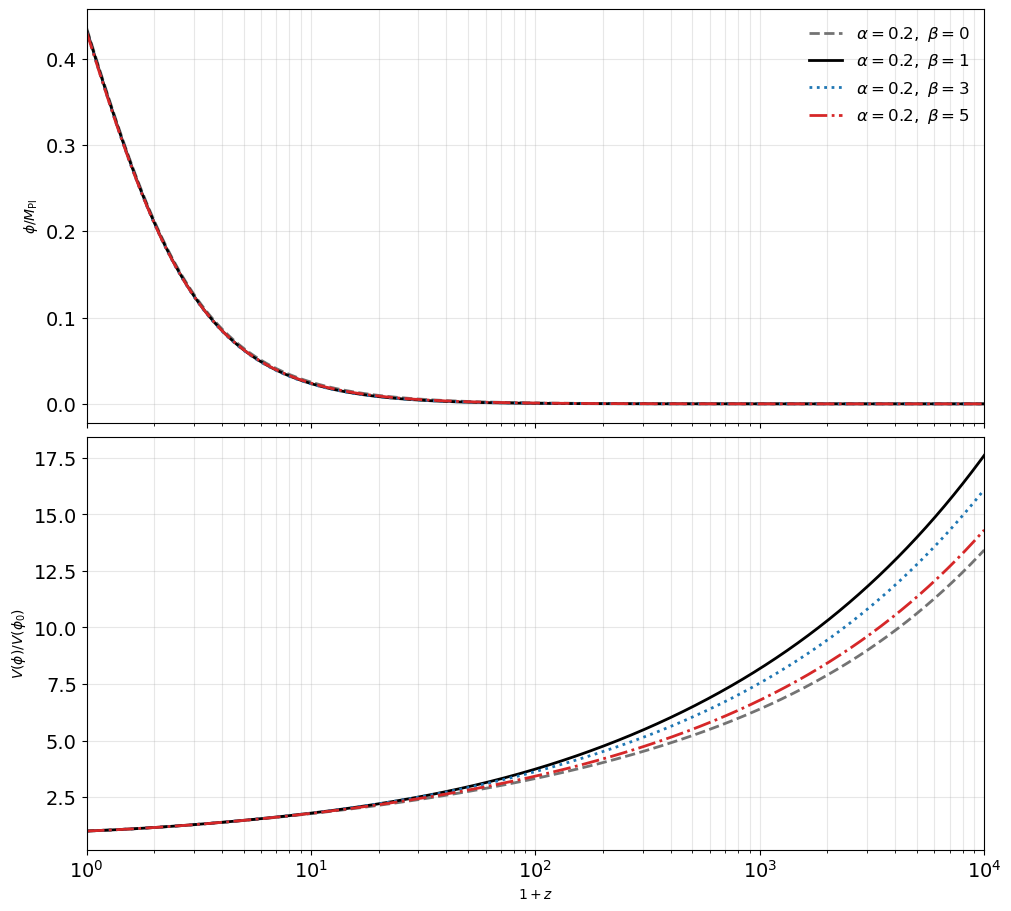

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True,
                         layout="constrained")

for result, label, color, ls in zip(data, labels, colors, linestyles):
    order = np.argsort(result["z"])
    z = result["z"][order]
    mask = z <= 1.0e4

    axes[0].semilogx(
        1.0 + z[mask], result["phi"][order][mask],
        color=color, linestyle=ls, linewidth=2, label=label,
    )
    axes[1].semilogx(
        1.0 + z[mask], result["potential_over_today"][order][mask],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

axes[0].set_ylabel(r"$\phi/M_{\rm Pl}$")
axes[1].set_ylabel(r"$V(\phi)/V(\phi_0)$")
axes[1].set_xlabel(r"$1+z$")
axes[1].set_xlim(1.0, 1.0e4)

for ax in axes:
    ax.tick_params(axis="both", which="major", labelsize=14)
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=12, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "phi_and_potential_vs_z.pdf", bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "phi_and_potential_vs_z.png", dpi=220,
                bbox_inches="tight")
plt.show()


## Effective neutrino mass


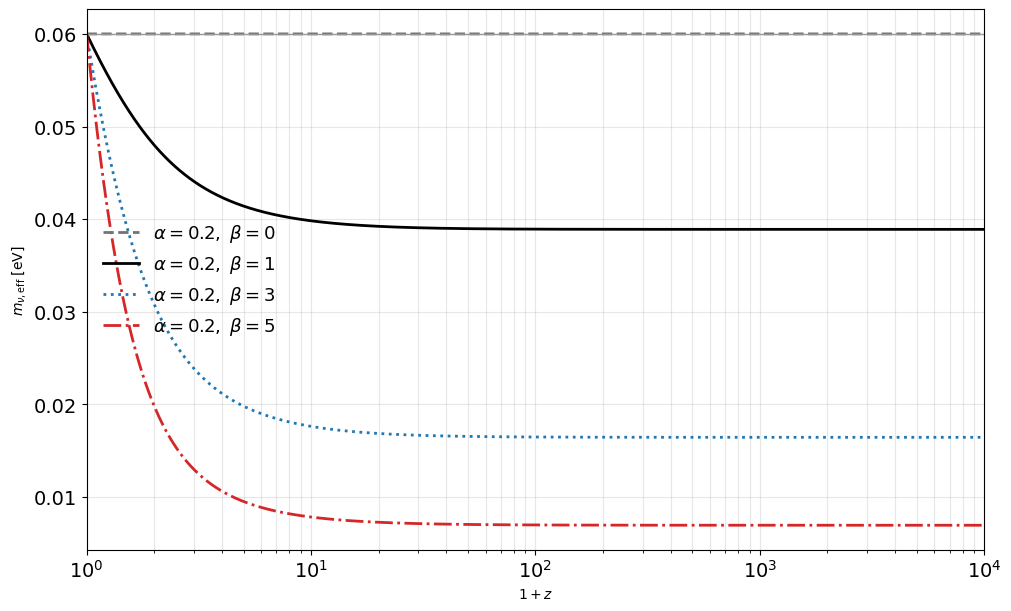

In [9]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for result, label, color, ls in zip(data, labels, colors, linestyles):
    order = np.argsort(result["z"])
    ax.semilogx(
        1.0 + result["z"][order], result["mnu"][order],
        color=color, linestyle=ls, linewidth=2, label=label,
    )

ax.axhline(MNU0_EV, color="0.6", linewidth=1.0)
ax.set(
    xlabel=r"$1+z$",
    ylabel=r"$m_{\nu,\mathrm{eff}}\;[\mathrm{eV}]$",
    xlim=(1.0, 1.0e4),
)
ax.tick_params(axis="both", which="major", labelsize=14)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=13, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "m_eff_vs_z.pdf", bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "m_eff_vs_z.png", dpi=220,
                bbox_inches="tight")
plt.show()


## CMB temperature spectrum \(D_\ell^{TT}\)


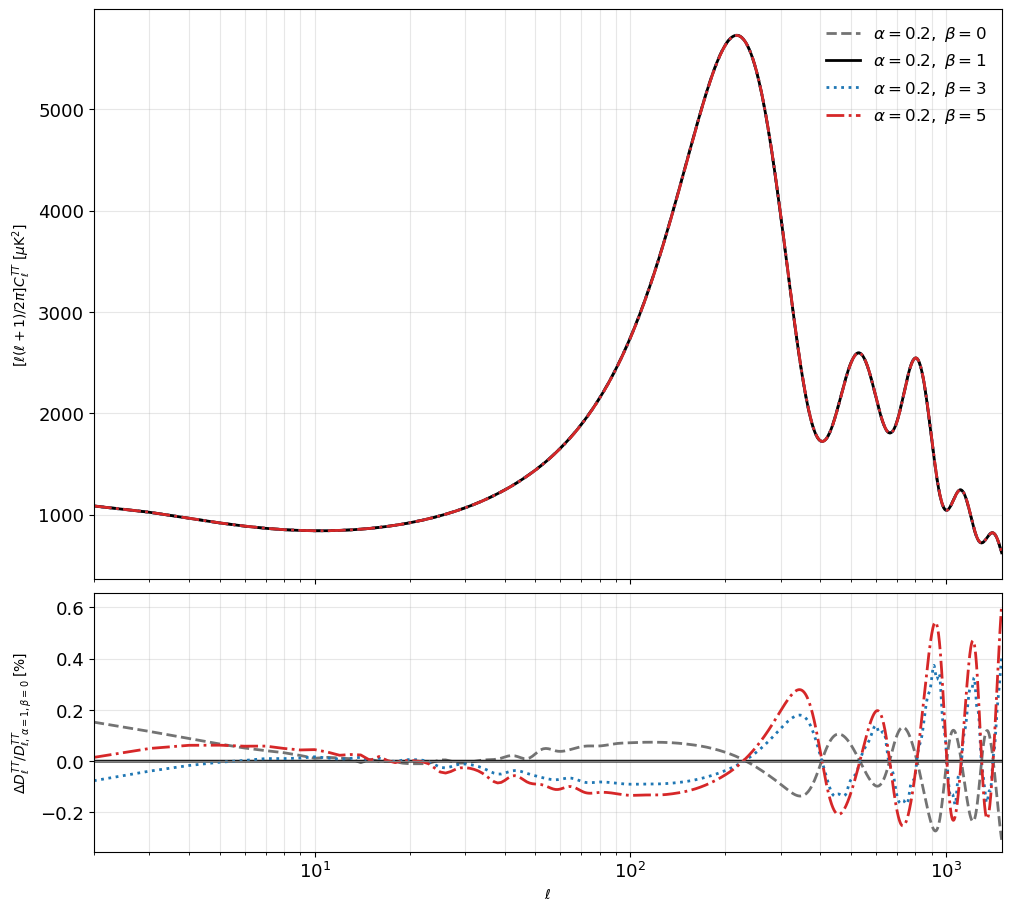

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1.0]},
                         layout="constrained")

# The uncoupled alpha=1 Ratra-Peebles case is the comparison reference.
reference = spectra[1]
for spectrum, label, color, ls in zip(
    spectra, labels, colors, linestyles
):
    mask = (spectrum["ell"] >= 2) & (spectrum["ell"] <= ELL_PLOT_MAX)
    ell = spectrum["ell"][mask]
    dl = spectrum["dl_tt"][mask]
    dl_ref = np.interp(ell, reference["ell"], reference["dl_tt"])

    axes[0].semilogx(
        ell, dl, color=color, linestyle=ls, linewidth=2, label=label,
    )
    axes[1].semilogx(
        ell, 100.0 * (divide(dl, dl_ref) - 1.0),
        color=color, linestyle=ls, linewidth=2,
    )

axes[0].set_ylabel(
    r"$[\ell(\ell+1)/2\pi]C_\ell^{TT}\;[\mu\mathrm{K}^2]$"
)
axes[1].set(
    xlabel=r"$\ell$",
    ylabel=r"$\Delta D_\ell^{TT}/D_{\ell,\,\alpha=1,\beta=0}^{TT}\;[\%]$",
    xlim=(2, ELL_PLOT_MAX),
)
axes[1].axhline(0.0, color="0.5", linewidth=1.0)
for ax in axes:
    ax.tick_params(axis="both", which="major", labelsize=13)
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=12, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "cltt_ratra_peebles.pdf", bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "cltt_ratra_peebles.png", dpi=220,
                bbox_inches="tight")
plt.show()


## Matter power spectrum and fractional change


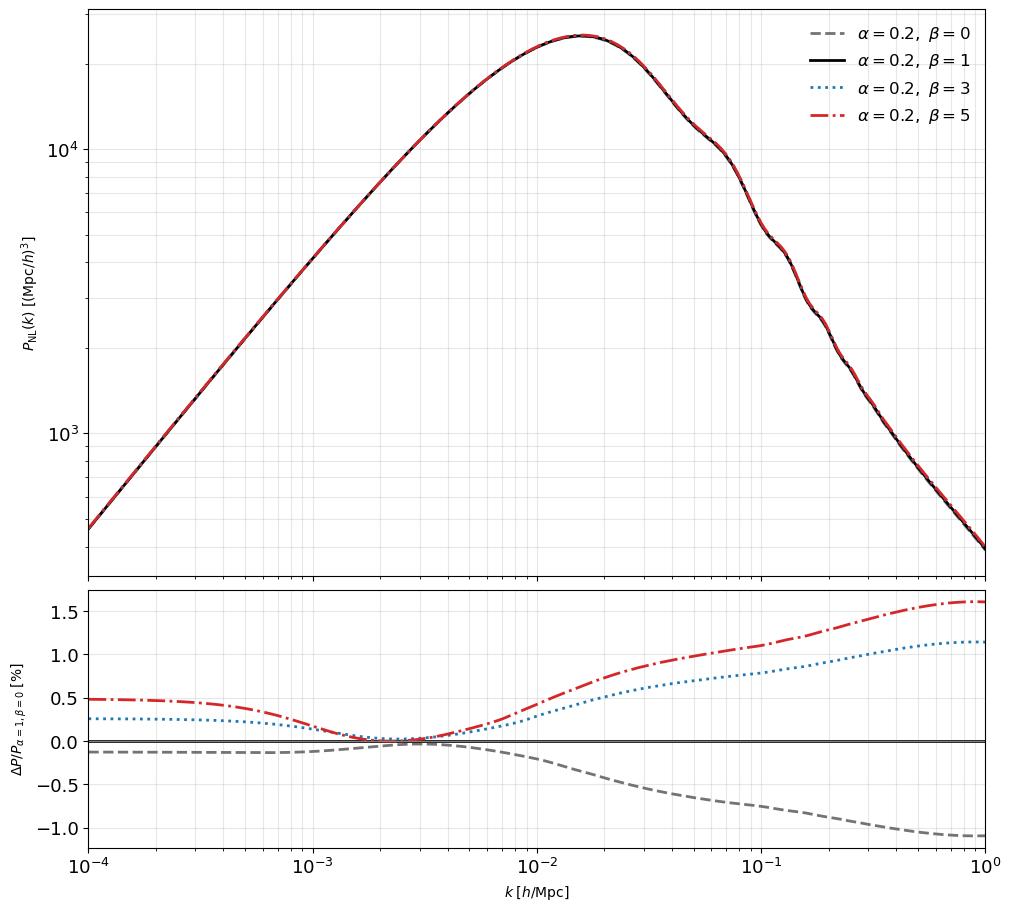

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(10, 9), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1.0]},
                         layout="constrained")

reference_pk = spectra[1]["pk"]
for spectrum, label, color, ls in zip(
    spectra, labels, colors, linestyles
):
    axes[0].loglog(
        K_H_MPC, spectrum["pk"],
        color=color, linestyle=ls, linewidth=2, label=label,
    )
    axes[1].semilogx(
        K_H_MPC, 100.0 * (divide(spectrum["pk"], reference_pk) - 1.0),
        color=color, linestyle=ls, linewidth=2,
    )

pk_label = r"$P_{\rm NL}(k)\;[(\mathrm{Mpc}/h)^3]$" if USE_NONLINEAR_PK \
    else r"$P_{\rm lin}(k)\;[(\mathrm{Mpc}/h)^3]$"
axes[0].set_ylabel(pk_label)
axes[1].set(
    xlabel=r"$k\;[h/\mathrm{Mpc}]$",
    ylabel=r"$\Delta P/P_{\alpha=1,\beta=0}\;[\%]$",
    xlim=(K_H_MPC[0], K_H_MPC[-1]),
)
axes[1].axhline(0.0, color="0.5", linewidth=1.0)
for ax in axes:
    ax.tick_params(axis="both", which="major", labelsize=13)
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=12, frameon=False)

if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / "pk_ratra_peebles.pdf", bbox_inches="tight")
    fig.savefig(FIGURE_DIR / "pk_ratra_peebles.png", dpi=220,
                bbox_inches="tight")
plt.show()


## Intrinsic, interacting-effective, and apparent equations of state


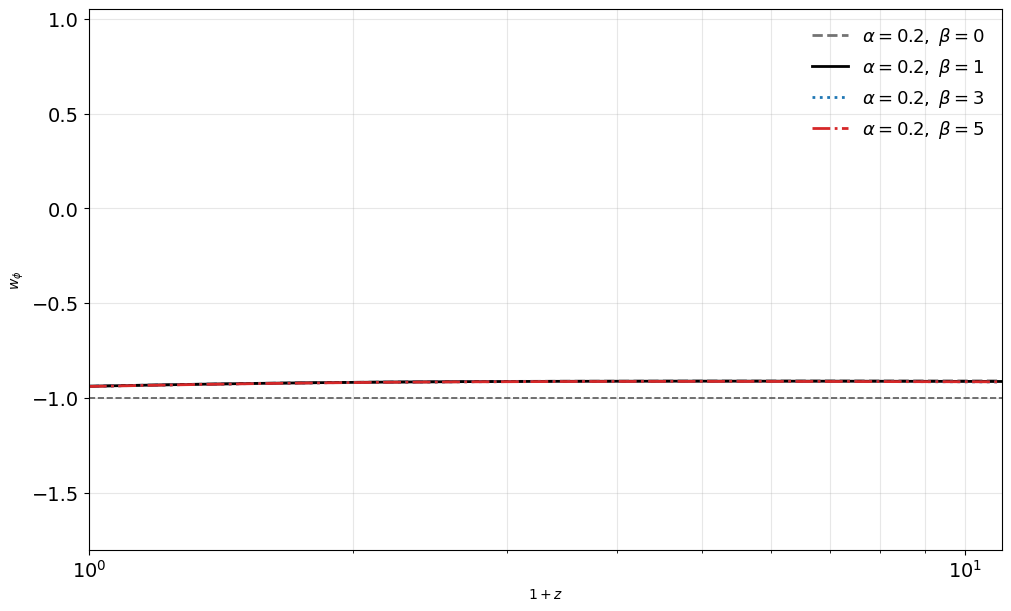

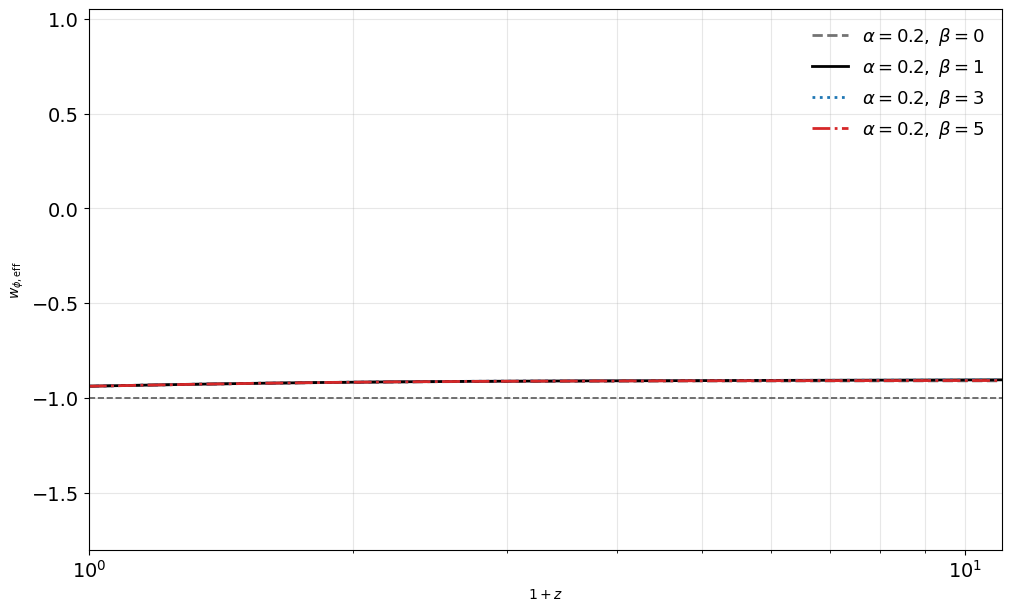

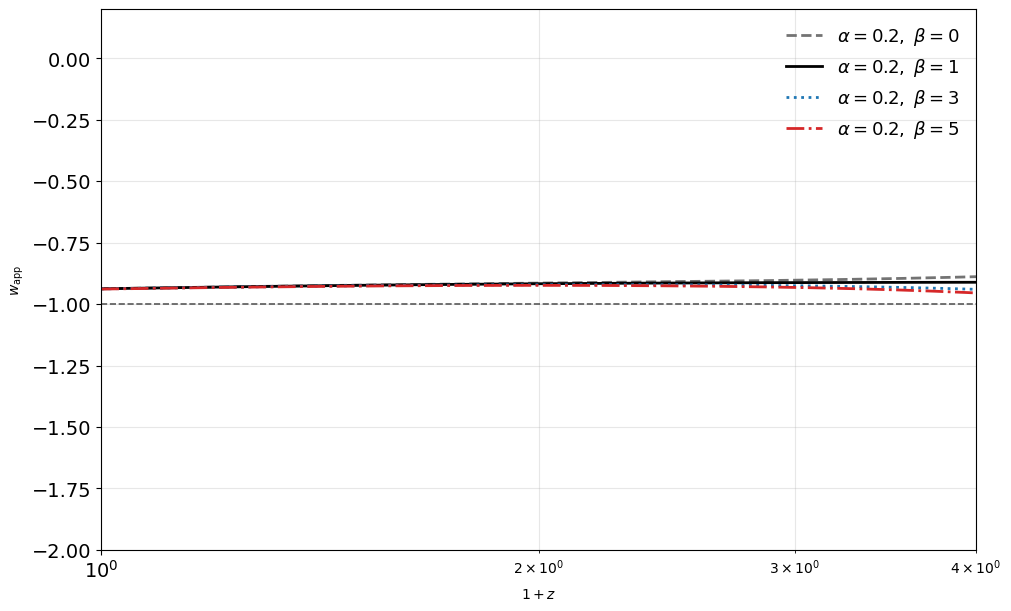

In [12]:
def plot_eos(key, ylabel, filename, zmax, ylim):
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

    for result, label, color, ls in zip(
        data, labels, colors, linestyles
    ):
        mask = (result["z"] >= 0.0) & (result["z"] <= zmax)
        order = np.argsort(result["z"][mask])
        z = result["z"][mask][order]
        eos = result[key][mask][order]

        ax.plot(
            1.0 + z, eos,
            color=color, linestyle=ls, linewidth=2, label=label,
        )

    ax.set_xscale("log")
    ax.set(
        xlabel=r"$1+z$",
        ylabel=ylabel,
        xlim=(1.0, 1.0 + zmax),
        ylim=ylim,
    )
    ax.axhline(-1.0, color="0.35", linestyle="--", linewidth=1.2)
    ax.tick_params(axis="both", which="major", labelsize=14)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=13, frameon=False)

    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.show()


plot_eos(
    "w_phi", r"$w_\phi$", "w_phi_eos_ratra.pdf",
    Z_BACKGROUND_MAX, (-1.8, 1.05),
)

plot_eos(
    "w_phi_eff", r"$w_{\phi,\mathrm{eff}}$", "w_phi_eff_eos_ratra.pdf",
    Z_BACKGROUND_MAX, (-1.8, 1.05),
)

# At higher redshift rho_DE,app can cross zero, giving a pole in w_app
# even though the physical background remains regular.
plot_eos(
    "w_app", r"$w_{\mathrm{app}}$", "w_app_eos_ratra.pdf",
    Z_APPARENT_MAX, (-2.0, 0.2),
)
